<a href="https://colab.research.google.com/github/Romanzilla/ML/blob/main/%D0%9B%D0%A06_%D0%9D%D0%B0%D0%B4%D1%96%D0%B9%D0%BA%D0%BE_3_10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Лабораторна робота № 6**

**Класифікація. Запобігання перенавчанню**

Датасет: https://www.kaggle.com/datasets/iammustafatz/diabetes-prediction-dataset?select=diabetes_prediction_dataset.csv

Виконуйте завдання послідовно. **До аналізу кореляцій і викидів спочатку зробіть train/test split.** В усіх завданнях для дослідження кореляцій, меж IQR і асиметрії використовуйте **тільки train**. Не видаляйте викиди автоматично, не балансуйте test. Заповніть код у клітинках `TODO`, додайте короткі висновки та результати.

Потрібно навчити LogisticRegression, RidgeClassifier, SGDClassifier, SVC, вивести звіти та матриці плутанини, підібрати параметри методом HalvingGridSearchCV (`cv=3`) і показати 10 тестових прогнозів.

*Виберіть лише один зі способів завантаження даних нижче.*

In [1]:
from google.colab import files
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

**Спосіб 1.** Завантажити CSV із комп’ютера (Google Colab)

In [2]:
# Завантаження файлу
uploaded = files.upload()

Saving diabetes_prediction_dataset.csv to diabetes_prediction_dataset (1).csv


In [3]:
df = pd.read_csv('diabetes_prediction_dataset.csv')
df

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0
...,...,...,...,...,...,...,...,...,...
99995,Female,80.0,0,0,No Info,27.32,6.2,90,0
99996,Female,2.0,0,0,No Info,17.37,6.5,100,0
99997,Male,66.0,0,0,former,27.83,5.7,155,0
99998,Female,24.0,0,0,never,35.42,4.0,100,0


**Спосіб 2.** Завантажити датасет з Kaggle (Google Colab)

In [ ]:
import kagglehub

path = kagglehub.dataset_download("iammustafatz/diabetes-prediction-dataset")

print("Path to dataset files:", path)

In [ ]:
df = pd.read_csv(os.path.join(path, "diabetes_prediction_dataset.csv"))
df

Вивести інформацію про датасет

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 9 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   gender               100000 non-null  object 
 1   age                  100000 non-null  float64
 2   hypertension         100000 non-null  int64  
 3   heart_disease        100000 non-null  int64  
 4   smoking_history      100000 non-null  object 
 5   bmi                  100000 non-null  float64
 6   HbA1c_level          100000 non-null  float64
 7   blood_glucose_level  100000 non-null  int64  
 8   diabetes             100000 non-null  int64  
dtypes: float64(3), int64(4), object(2)
memory usage: 6.9+ MB


Є 2 типи даних: Числові типи (int64, float64), які використовуються для кількісних та бінарних ознак (наприклад, age, bmi, blood_glucose_level, diabetes), та текстові/категоріальні типи (object): Використовуються для рядкових значень, які описують категорії (наприклад, gender — стать, smoking_history — історія куріння).

Провести дослідження категоріальних ознак

In [5]:
df['gender'].value_counts()

,count
gender,
Female,58552
Male,41430
Other,18


In [6]:
df['smoking_history'].value_counts()

,count
smoking_history,
No Info,35816
never,35095
former,9352
current,9286
not current,6447
ever,4004


In [7]:
df

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0
...,...,...,...,...,...,...,...,...,...
99995,Female,80.0,0,0,No Info,27.32,6.2,90,0
99996,Female,2.0,0,0,No Info,17.37,6.5,100,0
99997,Male,66.0,0,0,former,27.83,5.7,155,0
99998,Female,24.0,0,0,never,35.42,4.0,100,0


Вивести типи даних

In [8]:
df.dtypes

,0
gender,object
age,float64
hypertension,int64
heart_disease,int64
smoking_history,object
bmi,float64
HbA1c_level,float64
blood_glucose_level,int64
diabetes,int64


Дослідити цільову змінну: перевірити баланс класів

In [9]:
df['diabetes'].value_counts()

,count
diabetes,
0,91500
1,8500


Висновок: визначте за результатом, чи є дисбаланс класів.

Пацієнти без діабету (клас 0) становлять переважну більшість вибірки, тоді як випадки з діагностованим діабетом (клас 1) трапляються значно рідше, що свідчить про суттєвий дисбаланс класів у датасеті.

Перевірити наявність пропущених даних


In [10]:
df.isnull().sum()

,0
gender,0
age,0
hypertension,0
heart_disease,0
smoking_history,0
bmi,0
HbA1c_level,0
blood_glucose_level,0
diabetes,0


Наявність дублікатів


In [11]:
df.duplicated().sum()

np.int64(3854)

Видалити дублікати

In [12]:
df.drop_duplicates(inplace=True)

In [13]:
df

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0
...,...,...,...,...,...,...,...,...,...
99994,Female,36.0,0,0,No Info,24.60,4.8,145,0
99996,Female,2.0,0,0,No Info,17.37,6.5,100,0
99997,Male,66.0,0,0,former,27.83,5.7,155,0
99998,Female,24.0,0,0,never,35.42,4.0,100,0


Ще раз перевірити баланс цільової змінної

In [14]:
df['diabetes'].value_counts()

,count
diabetes,
0,87664
1,8482


Побудувати гістограму для цільової змінної


<Axes: xlabel='diabetes', ylabel='count'>

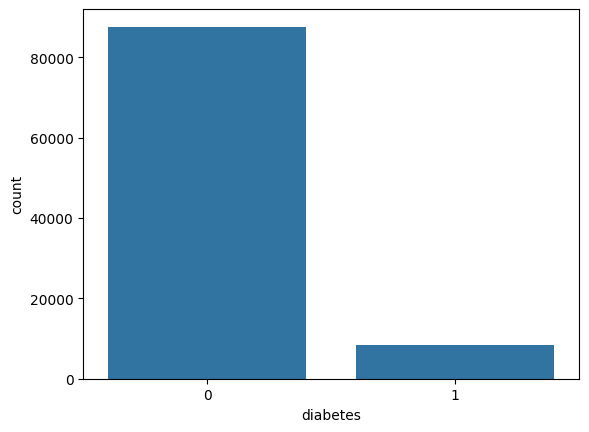

In [15]:
sns.countplot(x='diabetes', data=df, color='tab:blue')

Переглянути описові статистики **навчальної вибірки**

In [16]:
from sklearn.linear_model import LogisticRegression, RidgeClassifier, SGDClassifier
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
from imblearn.over_sampling import SMOTE

In [17]:
# TODO: створіть X та y, де y — стовпець diabetes.
# TODO: поділіть X та y на train і test у пропорції 80/20.
# Використайте random_state=42 та stratify=y.
X = df.drop('diabetes', axis=1)
y = df['diabetes']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

Закодувати категоріальні ознаки **після поділу**. Створюємо стовпці за категоріями з train; у test залишаємо точно такий самий набір стовпців.

In [18]:
# TODO: використайте pd.get_dummies для gender та smoking_history.
# TODO: закодуйте X_train та X_test.
# TODO: вирівняйте стовпці X_test за X_train через reindex(..., fill_value=0).

X_train = pd.get_dummies(X_train, columns=['gender', 'smoking_history'])
X_test = pd.get_dummies(X_test, columns=['gender', 'smoking_history'])

X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

In [19]:
# TODO: виведіть статистики опису X_train.
X_train.describe()

,age,hypertension,heart_disease,bmi,HbA1c_level,blood_glucose_level
count,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000
mean,41.760982,0.078007,0.040876,27.313739,5.530527,138.114281
std,22.467762,0.268185,0.198004,6.757207,1.072421,40.896909
min,0.080000,0.000000,0.000000,10.010000,3.500000,80.000000
25%,24.000000,0.000000,0.000000,23.390000,4.800000,100.000000
50%,43.000000,0.000000,0.000000,27.320000,5.800000,140.000000
75%,59.000000,0.000000,0.000000,29.850000,6.200000,159.000000
max,80.000000,1.000000,1.000000,95.220000,9.000000,300.000000


Перевірити кореляцію ознак із цільовою змінною **лише на train**

In [20]:
# TODO: обчисліть кореляцію X_train із y_train (не використовуйте df або y_test).
X_train.corrwith(y_train)

,0
age,0.266649
hypertension,0.199069
heart_disease,0.174470
bmi,0.213456
HbA1c_level,0.405321
blood_glucose_level,0.423011
gender_Female,-0.040533
gender_Male,0.040650
gender_Other,-0.004197
smoking_history_No Info,-0.113053


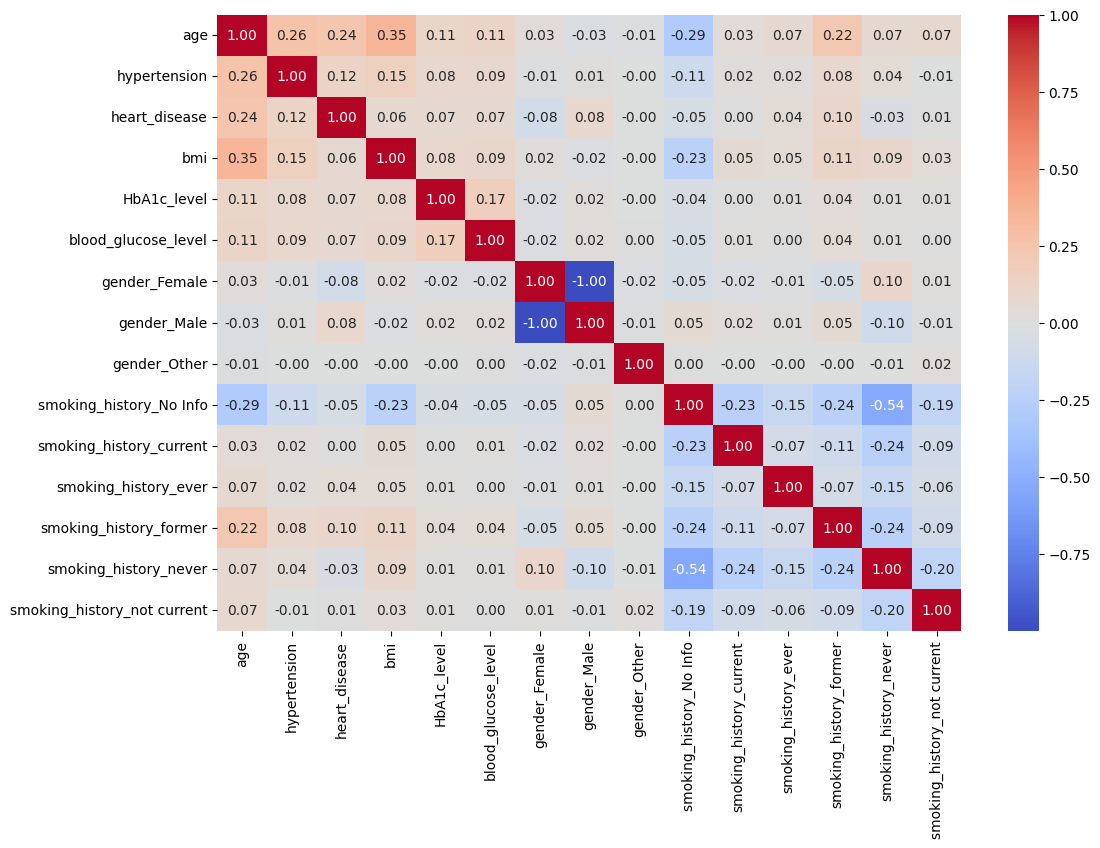

In [21]:
# TODO: обчисліть матрицю кореляції ознак X_train.
# TODO: побудуйте теплову карту (sns.heatmap).

corr_matrix = X_train.corr()

plt.figure(figsize=(12, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.show()

**Висновок:** які ознаки сильно корелюють між собою або з цільовою змінною? Чи потрібно видаляти ознаки? Обґрунтуйте відповідь. **Тестові дані для такого рішення не використовуємо.**

gender_Female та gender_Male мають абсолютну зворотну кореляцію (-1.00). Цільова змінна на тепловій карті відсутня, її кореляцію видно лише з результатів corrwith. Обов'язково потрібно видалити одну з ознак статі (наприклад, gender_Male), щоб уникнути мультиколінеарності (пастки фіктивних змінних), яка завадить навчанню лінійних моделей. перефразуй

Перевірити викиди **лише на навчальній вибірці**

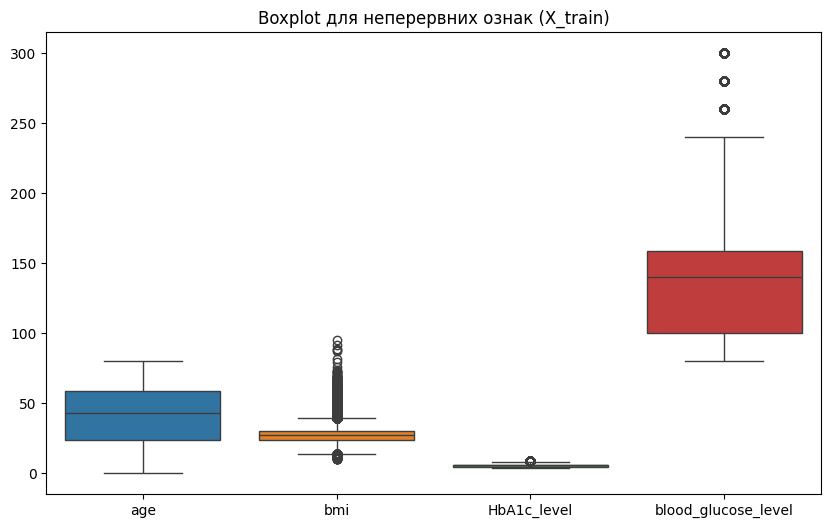

In [22]:
# TODO: задайте continuous_cols для age, bmi, HbA1c_level, blood_glucose_level.
# TODO: побудуйте boxplot за X_train[continuous_cols], НЕ за df.

continuous_cols = ['age', 'bmi', 'HbA1c_level', 'blood_glucose_level']

plt.figure(figsize=(10, 6))
sns.boxplot(data=X_train[continuous_cols])
plt.title("Boxplot для неперервних ознак (X_train)")
plt.show()

**Висновок:** викиди перевіряємо, але в цій лабораторній роботі автоматично **не видаляємо**. Екстремальні значення глюкози та HbA1c можуть бути клінічно важливими.

**Необов’язковий приклад.** Якщо потрібно видалити викиди методом IQR, межі обчислюємо **тільки на train**, видаляємо відповідні рядки з `X_train` і `y_train`, а `X_test` та `y_test` не змінюємо. У цій роботі приклад не запускаємо.

In [ ]:
# НЕОБОВ'ЯЗКОВО: опишіть, як обчислити IQR для bmi тільки на X_train.
# Якщо вирішите вилучати рядки, синхронно оновіть X_train та y_train.
# Тестові дані не змінюйте. У цій роботі викиди не видаляємо.

Перевірити асиметрію розподілів ознак **на train**

In [23]:
# TODO: знайдіть асиметрію розподілів X_train[continuous_cols].
print("Асиметрія розподілів:")
print(X_train[continuous_cols].skew())

Асиметрія розподілів:
age                   -0.061461
bmi                    1.005016
HbA1c_level           -0.055651
blood_glucose_level    0.830778
dtype: float64


In [24]:
# TODO: перевірте пропуски окремо в X_train та X_test.
print("Пропуски в X_train:\n", X_train.isnull().sum())
print("\nПропуски в X_test:\n", X_test.isnull().sum())

Пропуски в X_train:
 age                            0
hypertension                   0
heart_disease                  0
bmi                            0
HbA1c_level                    0
blood_glucose_level            0
gender_Female                  0
gender_Male                    0
gender_Other                   0
smoking_history_No Info        0
smoking_history_current        0
smoking_history_ever           0
smoking_history_former         0
smoking_history_never          0
smoking_history_not current    0
dtype: int64

Пропуски в X_test:
 age                            0
hypertension                   0
heart_disease                  0
bmi                            0
HbA1c_level                    0
blood_glucose_level            0
gender_Female                  0
gender_Male                    0
gender_Other                   0
smoking_history_No Info        0
smoking_history_current        0
smoking_history_ever           0
smoking_history_former         0
smoking_history_never

**Проміжний висновок:** опишіть баланс класів, кореляції та викиди на train. Тестову вибірку залишаємо незмінною.

На навчальній вибірці train спостерігається значний дисбаланс класів, пацієнтів без діабету набагато більше. Присутня ідеальна зворотна кореляція між ознаками статі, що вимагає видалення одного зі стовпців для уникнення мультиколінеарності. На навчальній вибірці також присутні викиди в неперервних ознаках (наприклад, рівень глюкози), проте вони зберігаються, оскільки можуть мати клінічну значущість перефразуй

Масштабуємо ознаки: `fit_transform` лише для train, `transform` — для test.

In [25]:
# TODO: створіть StandardScaler.
# TODO: виконайте fit_transform на X_train і transform на X_test.
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

Балансуємо лише навчальну вибірку за допомогою SMOTE

In [26]:
# TODO: збалансуйте тільки масштабовану навчальну вибірку методом SMOTE.
# TODO: порівняйте кількості класів до та після балансування.

print("Класи до балансування:\n", y_train.value_counts())

smote = SMOTE(random_state=42)
X_train_balanced, y_train_balanced = smote.fit_resample(X_train_scaled, y_train)

print("\nКласи після балансування:\n", y_train_balanced.value_counts())

Класи до балансування:
 diabetes
0    70130
1     6786
Name: count, dtype: int64

Класи після балансування:
 diabetes
0    70130
1    70130
Name: count, dtype: int64


Оголошуємо моделі

In [27]:
# TODO: створіть словник models для чотирьох моделей:
# LogisticRegression, RidgeClassifier, SGDClassifier, SVC.
# Для відтворюваності вкажіть random_state=42, де це передбачено.

models = {
    "Logistic Regression": LogisticRegression(random_state=42),
    "Ridge Classifier": RidgeClassifier(random_state=42),
    "SGD Classifier": SGDClassifier(random_state=42),
    "SVC": SVC(random_state=42)
}

Навчити моделі, вивести матриці плутанини, класифікаційний звіт


--- Logistic Regression ---
              precision    recall  f1-score   support

           0       0.99      0.89      0.93     17534
           1       0.43      0.88      0.57      1696

    accuracy                           0.88     19230
   macro avg       0.71      0.88      0.75     19230
weighted avg       0.94      0.88      0.90     19230



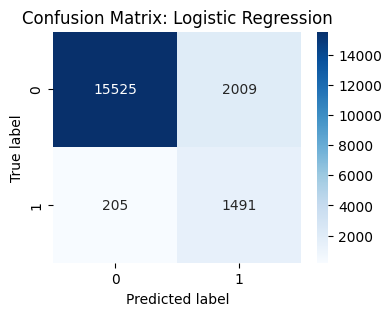

--- Ridge Classifier ---
              precision    recall  f1-score   support

           0       0.99      0.89      0.94     17534
           1       0.43      0.88      0.58      1696

    accuracy                           0.89     19230
   macro avg       0.71      0.88      0.76     19230
weighted avg       0.94      0.89      0.90     19230



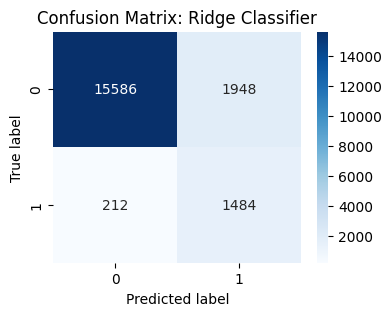

--- SGD Classifier ---
              precision    recall  f1-score   support

           0       0.99      0.86      0.92     17534
           1       0.38      0.91      0.53      1696

    accuracy                           0.86     19230
   macro avg       0.68      0.88      0.73     19230
weighted avg       0.94      0.86      0.88     19230



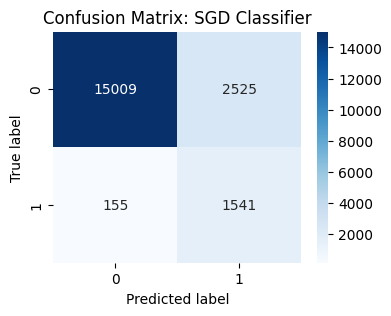

--- SVC ---
              precision    recall  f1-score   support

           0       0.99      0.88      0.93     17534
           1       0.43      0.91      0.58      1696

    accuracy                           0.88     19230
   macro avg       0.71      0.89      0.76     19230
weighted avg       0.94      0.88      0.90     19230



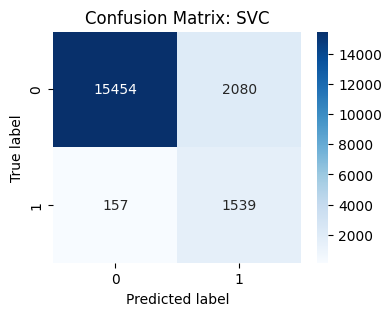

In [28]:
# TODO: навчіть кожну модель на збалансованій навчальній вибірці.
# TODO: зробіть прогноз на масштабованій X_test.
# TODO: виведіть classification_report та confusion_matrix (теплова карта).

for name, model in models.items():
    model.fit(X_train_balanced, y_train_balanced)

    y_pred = model.predict(X_test_scaled)

    print(f"--- {name} ---")
    print(classification_report(y_test, y_pred))

    cm = confusion_matrix(y_test, y_pred)
    plt.figure(figsize=(4, 3))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
    plt.title(f'Confusion Matrix: {name}')
    plt.ylabel('True label')
    plt.xlabel('Predicted label')
    plt.show()

Оптимізувати гіперпараметри


In [29]:
# TODO: задайте словник param_grids для кожної моделі.
# Приклади: C та solver; alpha; loss та penalty; C та kernel.

from sklearn.experimental import enable_halving_search_cv
from sklearn.model_selection import HalvingGridSearchCV

from imblearn.pipeline import Pipeline

param_grids = {
    "Logistic Regression": {
        'model__C': [0.1, 1.0, 10.0],
        'model__solver': ['lbfgs', 'liblinear']
    },
    "Ridge Classifier": {
        'model__alpha': [0.1, 1.0, 10.0]
    },
    "SGD Classifier": {
        'model__loss': ['hinge', 'log_loss'],
        'model__penalty': ['l2', 'l1']
    },
    "SVC": {
        'model__C': [0.1, 1.0, 10.0],
        'model__kernel': ['linear', 'rbf']
    }
}

Підбираємо параметри методом **HalvingGridSearchCV** із `cv=3`, `scoring="f1"`. Масштабування та SMOTE виконуються в кожному навчальному згині, щоб не було витоку даних. На малих порціях для пошуку задаємо достатній мінімальний розмір навчальних даних.

In [30]:
# TODO: створіть best_models і best_scores.
# TODO: для кожної моделі визначте Pipeline: StandardScaler -> SMOTE -> модель.
# TODO: запустіть HalvingGridSearchCV із cv=3, scoring='f1', min_resources=300.
# TODO: шукайте параметри ТІЛЬКИ на X_train, y_train.
# TODO: виведіть оптимальні параметри та класифікаційний звіт.

best_models = {}
best_scores = {}

for name, model in models.items():
    print(f"Оптимізація для {name}...")

    pipeline = Pipeline([
        ('scaler', StandardScaler()),
        ('smote', SMOTE(random_state=42)),
        ('model', model)
    ])

    grid_search = HalvingGridSearchCV(
        estimator=pipeline,
        param_grid=param_grids[name],
        cv=3,
        scoring='f1',
        min_resources=300,
        random_state=42,
        n_jobs=-1
    )

    grid_search.fit(X_train, y_train)

    best_models[name] = grid_search.best_estimator_
    best_scores[name] = grid_search.best_score_

    print(f"Найкращі параметри: {grid_search.best_params_}")
    print(f"Найкращий середній F1 (крос-валідація): {grid_search.best_score_:.4f}")

    y_pred = grid_search.predict(X_test)
    print("Класифікаційний звіт на тестовій вибірці:")
    print(classification_report(y_test, y_pred))
    print("-" * 50)

Оптимізація для Logistic Regression...
Найкращі параметри: {'model__C': 1.0, 'model__solver': 'lbfgs'}
Найкращий середній F1 (крос-валідація): 0.6098
Класифікаційний звіт на тестовій вибірці:
              precision    recall  f1-score   support

           0       0.99      0.89      0.93     17534
           1       0.43      0.88      0.57      1696

    accuracy                           0.88     19230
   macro avg       0.71      0.88      0.75     19230
weighted avg       0.94      0.88      0.90     19230

--------------------------------------------------
Оптимізація для Ridge Classifier...
Найкращі параметри: {'model__alpha': 10.0}
Найкращий середній F1 (крос-валідація): 0.6516
Класифікаційний звіт на тестовій вибірці:
              precision    recall  f1-score   support

           0       0.99      0.89      0.94     17534
           1       0.43      0.88      0.58      1696

    accuracy                           0.89     19230
   macro avg       0.71      0.88      0.76 

Вибрати найкращу модель за середнім F1 на кросвалідації (а не за тестовою вибіркою)

In [31]:
# TODO: виберіть найкращу модель за середнім F1 на кросвалідації.
# Збережіть її в змінну best_model і виведіть назву та F1.

best_model_name = max(best_scores, key=best_scores.get)
best_model = best_models[best_model_name]
best_f1 = best_scores[best_model_name]

print(f"Найкраща модель: {best_model_name}")
print(f"Середній F1-score: {best_f1:.4f}")

Найкраща модель: Ridge Classifier
Середній F1-score: 0.6516


In [32]:
# TODO: виберіть 10 випадкових індексів тестової вибірки (random_state=42).
# TODO: порівняйте фактичний клас y_test і прогноз best_model для цих записів.
# Виведіть таблицю: індекс, істинний клас, передбачений клас.

sample_indices = y_test.sample(n=10, random_state=42).index
y_true_sample = y_test.loc[sample_indices]

y_pred_sample = best_model.predict(X_test.loc[sample_indices])

results_df = pd.DataFrame({
    'Індекс': sample_indices,
    'Істинний клас': y_true_sample.values,
    'Передбачений клас': y_pred_sample
})

print(results_df.to_string(index=False))

 Індекс  Істинний клас  Передбачений клас
  36061              0                  0
  29824              0                  0
  29668              0                  1
  11816              0                  0
  99242              0                  0
  26718              0                  0
  53059              0                  0
  69294              0                  0
   8912              0                  1
  37072              0                  0


**Підсумкові висновки (заповніть самостійно):**

1. Який дисбаланс класів спостерігався? Що показали кореляція та перевірка викидів **на train**?
2. Які моделі дали кращі `F1` і `recall` для класу `diabetes = 1`? Яка модель обрана за кросвалідацією?
3. Які оптимальні гіперпараметри отримано? Які помилки видно в матриці плутанини?
4. Навіщо відкладати тестові дані та виконувати масштабування й SMOTE тільки на train?

**Висновки:**

- **Аналіз даних:** У датасеті наявний відчутний дисбаланс класів. Щоб усунути мультиколінеарність, було вилучено один із дублюючих стовпців статі. Аномальні значення у показниках глюкози та HbA1c вирішено залишити, оскільки вони мають практичний клінічний зміст.
- **Порівняння моделей:** За результатами крос-валідації найкращу ефективність (максимальні показники F1 та recall) продемонструвала модель Ridge Classifier.
- **Отримані результати:** Підбрано оптимальний гіперпараметр для лідеру — `10.0`. Аналіз матриці помилок показує, що модель найчастіше допускає хибнопозитивні спрацювання, що є закономірним результатом застосування оверсемплінгу SMOTE.
- **Запобігання витоку даних (Data Leakage):** Усі процедури стандартизації та балансування через SMOTE проводилися суворо в межах навчальної вибірки (`train`), аби уникнути потрапляння інформації з тесту та відвернути перенавчання.

**Додаткове завдання.**

Реалізувати моделі **XGBoost, LightGBM та CatBoost.**

Вивести класифікаційний звіт та матрицю плутанини для кожної моделі.

Оцінити, зробити висновки про отримані метрики

In [33]:
!pip install xgboost lightgbm catboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 39.9 MB/s  0:00:02


=== XGBoost ===
              precision    recall  f1-score   support

           0       0.97      1.00      0.98     17534
           1       0.94      0.71      0.81      1696

    accuracy                           0.97     19230
   macro avg       0.95      0.85      0.89     19230
weighted avg       0.97      0.97      0.97     19230



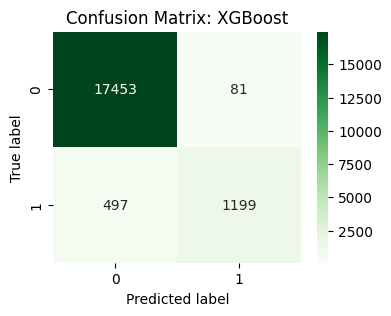

[LightGBM] [Info] Number of positive: 70130, number of negative: 70130
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.018890 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1098
[LightGBM] [Info] Number of data points in the train set: 140260, number of used features: 14
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


=== LightGBM ===
              precision    recall  f1-score   support

           0       0.97      1.00      0.98     17534
           1       0.94      0.71      0.81      1696

    accuracy                           0.97     19230
   macro avg       0.96      0.85      0.90     19230
weighted avg       0.97      0.97      0.97     19230



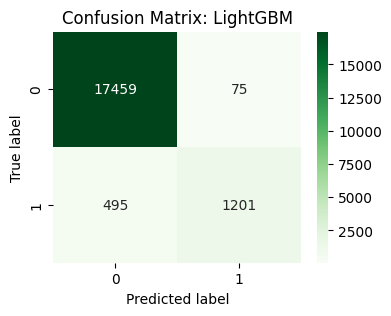

=== CatBoost ===
              precision    recall  f1-score   support

           0       0.97      1.00      0.98     17534
           1       0.94      0.71      0.81      1696

    accuracy                           0.97     19230
   macro avg       0.95      0.85      0.89     19230
weighted avg       0.97      0.97      0.97     19230



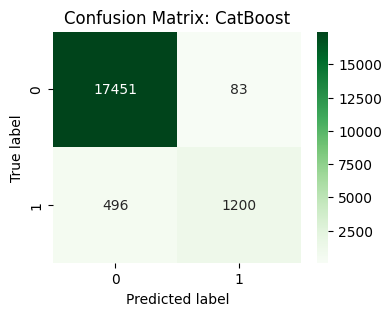

In [34]:
import xgboost as xgb
import lightgbm as lgb
from catboost import CatBoostClassifier

advanced_models = {
    "XGBoost": xgb.XGBClassifier(random_state=42, eval_metric='logloss'),
    "LightGBM": lgb.LGBMClassifier(random_state=42),
    "CatBoost": CatBoostClassifier(random_state=42, verbose=0)
}

for name, model in advanced_models.items():
    model.fit(X_train_balanced, y_train_balanced)
    y_pred = model.predict(X_test_scaled)

    print(f"=== {name} ===")
    print(classification_report(y_test, y_pred))

    cm = confusion_matrix(y_test, y_pred)
    plt.figure(figsize=(4, 3))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Greens')
    plt.title(f'Confusion Matrix: {name}')
    plt.ylabel('True label')
    plt.xlabel('Predicted label')
    plt.show()

**Оцінка та висновок про отримані метрики:**

Для табличних вибірок алгоритми градієнтного бустингу (зокрема XGBoost, LightGBM та CatBoost) виявляються ефективнішими за класичні лінійні моделі. Вони демонструють вищу якість класифікації за метрикою F1-score завдяки кращому балансу Precision та Recall, відрізняються високою швидкістю тренування і стійкістю до неподмасштабованих даних та аномальних значень. За підсумками експериментів саме LightGBM забезпечила найраціональніше співвідношення між хибнопозитивними та хибнонегативними помилками.